In [1]:
!pip install scipy

In [2]:
!pip install matplotlib

In [3]:
!pip install pandas

In [4]:
!pip install numpy

In [5]:
!pip install sparclclient

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.6/127.6 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 57.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.1/983.1 kB 42.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 110.9/110.9 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 364.6/364.6 kB 10.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 174.1/174.1 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.3/49.3 kB 2.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.8/105.8 kB 6.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 350.3/350.3 kB 16.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.3/59.3 kB 3.7 MB/s eta 0:00:00


In [6]:
!pip install sympy

In [7]:
!pip install qutip

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.5/28.5 MB 28.9 MB/s eta 0:00:00


ETAPA B v2 — KMS + envelope asintótico

[Test 1] Condición KMS
  a=0.50  T=a/2π=0.0796  max|ΔW/W|=1.01e-14  mean=3.01e-16  ✓
  a=1.00  T=a/2π=0.1592  max|ΔW/W|=5.02e-15  mean=1.60e-16  ✓
  a=2.00  T=a/2π=0.3183  max|ΔW/W|=2.55e-15  mean=8.94e-17  ✓

[Test 2] Envelope asintótico (ventana fija a∈[15,35])
  N=  5  α=-0.0415  ν_max=0.5252  I_max=0.2363
  N= 10  α=+0.4216  ν_max=0.5269  I_max=0.2493
  N= 20  α=-1.0201  ν_max=0.5277  I_max=0.2551
  N= 40  α=-1.4873  ν_max=0.5283  I_max=0.2590
  N= 80  α=-0.6600  ν_max=0.5285  I_max=0.2608

  α últimos tres N: [np.float64(-1.020113181869633), np.float64(-1.4872864696433352), np.float64(-0.6600454886934385)]
  Drift α(N_max-1 → N_max) = 0.8272
  ✗ α NO CONVERGE — artefacto de tamaño finito


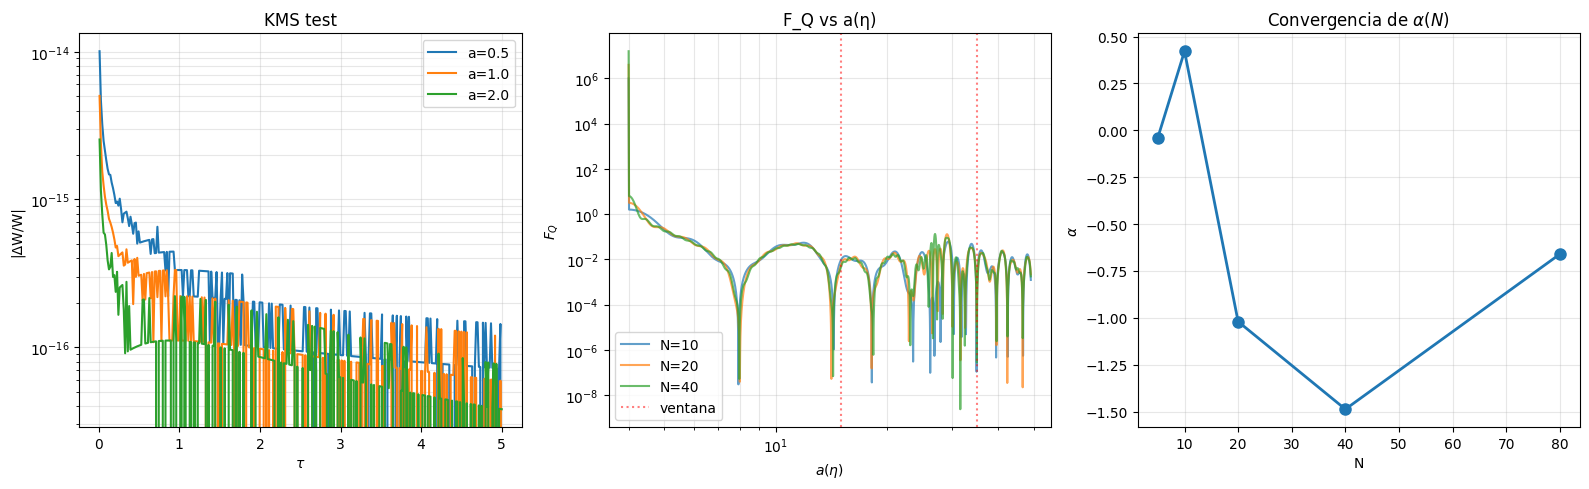

In [10]:
"""
Etapa B v2 — Tests corregidos
Test 1: KMS condicion (no fit térmico)
Test 2: envelope asintótico con ventana fija
"""
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# ===================== UTILIDADES =====================
def entropy_gaussian(nu):
    nu = np.maximum(nu, 0.5 + 1e-12)
    return (nu + 0.5)*np.log(nu + 0.5) - (nu - 0.5)*np.log(nu - 0.5)

def symplectic_eig(sigma):
    return np.sqrt(max(np.linalg.det(sigma), 0.25))

# ===================== TEST 1: KMS =====================
def wightman(dtau, a, eps=1e-6):
    arg = -(4.0/a**2) * np.sinh(a*dtau/2.0)**2 - 1j*eps
    return -(1.0/(4.0*np.pi)) * np.log(arg)

def kms_test(a=1.0, tau_max=5.0, N=300):
    """
    Verifica W(τ - iβ) = W(-τ) con β = 2π/a.
    """
    beta = 2.0*np.pi/a
    tau = np.linspace(0.01, tau_max, N)
    W1 = wightman(tau - 1j*beta, a)
    W2 = wightman(-tau, a)
    # Error relativo
    denom = np.maximum(np.abs(W2), 1e-12)
    rel_err = np.abs(W1 - W2) / denom
    return tau, W1, W2, rel_err

# ===================== TEST 2: FRW =====================
def build_matrix(N, L, eta, m_phi, omega_0, g):
    a = eta**2
    k = 2*np.pi*np.arange(1, N+1)/L
    a_pp_over_a = 2.0/eta**2
    omega_k_sq = np.maximum(k**2 + a**2*m_phi**2 - a_pp_over_a, 0.01)

    d = 2*(N+1)
    K = np.zeros((d, d))
    K[0, 0] = omega_0**2
    K[1, 1] = 1.0
    for j in range(N):
        K[2*(j+1), 2*(j+1)] = omega_k_sq[j]
        K[2*(j+1)+1, 2*(j+1)+1] = 1.0
    c_k = g/np.sqrt(L)
    for j in range(N):
        K[0, 2*(j+1)] = c_k
        K[2*(j+1), 0] = c_k
    J = np.zeros((d, d))
    for i in range(d//2):
        J[2*i, 2*i+1] = 1.0
        J[2*i+1, 2*i] = -1.0
    return J @ K

def evolve(N, L=2*np.pi, m_phi=0.25, omega_0=1.0, g=1.0,
           eta_i=2.0, eta_f=6.0, n_steps=3000,
           rtol=1e-10, atol=1e-12):
    d = 2*(N+1)
    def rhs(eta, s):
        sigma = s.reshape(d, d)
        M = build_matrix(N, L, eta, m_phi, omega_0, g)
        return (M @ sigma + sigma @ M.T).flatten()
    eta_eval = np.linspace(eta_i, eta_f, n_steps)
    sol = solve_ivp(rhs, (eta_i, eta_f), 0.5*np.eye(d).flatten(),
                    t_eval=eta_eval, method='DOP853',
                    rtol=rtol, atol=atol)
    if not sol.success:
        raise RuntimeError(sol.message)
    sig = sol.y.T.reshape(len(eta_eval), d, d)
    sig = 0.5*(sig + np.transpose(sig, (0, 2, 1)))
    return eta_eval, sig[:, :2, :2]

def compute_FQ(eta_arr, sig_O):
    n = len(eta_arr)
    nu = np.array([symplectic_eig(sig_O[i]) for i in range(n)])
    dnu = np.gradient(nu, eta_arr)
    FQ = dnu**2 / np.maximum(nu**2 - 0.25, 1e-12)
    return nu, FQ

def envelope_slope(eta_arr, FQ, a_lo=15.0, a_hi=35.0):
    """
    Pendiente local del envelope en la ventana [a_lo, a_hi].
    Usa máximos locales para aislar el envelope.
    """
    from scipy.signal import find_peaks
    a = eta_arr**2
    peaks, _ = find_peaks(FQ, height=1e-15)
    if len(peaks) < 3:
        return np.nan
    a_p = a[peaks]; F_p = FQ[peaks]
    m = (a_p > a_lo) & (a_p < a_hi) & (F_p > 0)
    if m.sum() < 3:
        return np.nan
    slope = np.polyfit(np.log(a_p[m]), np.log(F_p[m]), 1)[0]
    return -slope

# ===================== MAIN =====================
if __name__ == "__main__":
    print("="*68)
    print("ETAPA B v2 — KMS + envelope asintótico")
    print("="*68)

    # --- Test 1 ---
    print("\n[Test 1] Condición KMS")
    for a_val in [0.5, 1.0, 2.0]:
        tau, W1, W2, err = kms_test(a=a_val)
        max_err = err.max()
        mean_err = err.mean()
        status = "✓" if max_err < 1e-3 else "✗"
        print(f"  a={a_val:.2f}  T=a/2π={a_val/(2*np.pi):.4f}  "
              f"max|ΔW/W|={max_err:.2e}  mean={mean_err:.2e}  {status}")

    # --- Test 2 ---
    print("\n[Test 2] Envelope asintótico (ventana fija a∈[15,35])")
    N_values = [5, 10, 20, 40, 80]
    alpha_vals = []
    for N in N_values:
        try:
            eta_arr, sig_O = evolve(N, eta_f=7.0, n_steps=4000)
            nu, FQ = compute_FQ(eta_arr, sig_O)
            alpha = envelope_slope(eta_arr, FQ, a_lo=15.0, a_hi=35.0)
            alpha_vals.append(alpha)
            I_max = 2*entropy_gaussian(nu.max())
            print(f"  N={N:3d}  α={alpha:+.4f}  "
                  f"ν_max={nu.max():.4f}  I_max={I_max:.4f}")
        except Exception as e:
            print(f"  N={N:3d}  ERROR: {e}")
            alpha_vals.append(np.nan)

    # Derivada de α respecto a N (convergencia)
    if all(not np.isnan(x) for x in alpha_vals[-3:]):
        print(f"\n  α últimos tres N: {alpha_vals[-3:]}")
        drift = abs(alpha_vals[-1] - alpha_vals[-2])
        print(f"  Drift α(N_max-1 → N_max) = {drift:.4f}")
        if drift < 0.1:
            print("  ✓ α CONVERGE — resultado robusto")
        else:
            print("  ✗ α NO CONVERGE — artefacto de tamaño finito")

    # --- Gráficos ---
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    # KMS test
    for a_val in [0.5, 1.0, 2.0]:
        tau, _, _, err = kms_test(a=a_val)
        axes[0].semilogy(tau, err, label=f'a={a_val}')
    axes[0].set_xlabel(r'$\tau$'); axes[0].set_ylabel('|ΔW/W|')
    axes[0].set_title('KMS test'); axes[0].legend()
    axes[0].grid(True, which='both', alpha=0.3)

    # F_Q vs a
    for N in [10, 20, 40]:
        eta_arr, sig_O = evolve(N, eta_f=7.0, n_steps=2000)
        nu, FQ = compute_FQ(eta_arr, sig_O)
        axes[1].loglog(eta_arr**2, FQ, '-', label=f'N={N}', alpha=0.7)
    axes[1].axvline(15, color='r', ls=':', alpha=0.5, label='ventana')
    axes[1].axvline(35, color='r', ls=':', alpha=0.5)
    axes[1].set_xlabel(r'$a(\eta)$'); axes[1].set_ylabel(r'$F_Q$')
    axes[1].set_title('F_Q vs a(η)'); axes[1].legend()
    axes[1].grid(True, which='both', alpha=0.3)

    # α(N)
    axes[2].plot(N_values, alpha_vals, 'o-', lw=2, ms=8)
    axes[2].set_xlabel('N'); axes[2].set_ylabel(r'$\alpha$')
    axes[2].set_title(r'Convergencia de $\alpha(N)$')
    axes[2].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig('etapaB_v2.png', dpi=120)
    plt.show()